In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast

import sys
import os
from tqdm import tqdm

sys.path.insert(0, os.path.join(os.getcwd(), "..", "scripts"))
from utility_functions import overlap, true_not_predicted, predicted_not_true, charge, \
    make_tada_intervals, make_paddle_intervals, make_adhunter_intervals, not_predicted_not_true, AD_coords, \
    make_adhunter_ensemble_intervals, make_adpred_intervals

In [12]:
color_dict = {
    'TADA' : 'green',
    'ADpred' : 'dodgerblue',
    'ADhunterEnsemble' : 'red', 
    'ADhunterLite' : 'orange',
    'Paddle' : 'purple'
}

In [13]:
# Read in predictions from individual predictors
individual_predictions = pd.read_csv('delrosso_test_TFs_w_ADs_combined_all_six.csv',
                                     index_col=0, 
                                     converters={'combined_preds' : ast.literal_eval, 
                                                })

# Convert to lists of tuples
individual_predictions['adhunter_intervals'] = individual_predictions['adhunter_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adhunter_centers'] = individual_predictions['adhunter_centers'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adhunter_preds'] = individual_predictions['adhunter_preds'].fillna('[]').apply(ast.literal_eval)


individual_predictions['tada_intervals'] = individual_predictions['tada_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['tada_centers'] = individual_predictions['tada_centers'].fillna('[]').apply(ast.literal_eval)
individual_predictions['tada_preds'] = individual_predictions['tada_preds'].fillna('[]').apply(ast.literal_eval)

individual_predictions['adpred_intervals'] = individual_predictions['adpred_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adpred_preds'] = individual_predictions['adpred_preds'].fillna('[]').apply(ast.literal_eval)

individual_predictions['paddle_intervals'] = individual_predictions['paddle_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['paddle_centers'] = individual_predictions['paddle_centers'].apply(ast.literal_eval)
individual_predictions['paddle_preds'] = individual_predictions['paddle_preds'].apply(ast.literal_eval)

individual_predictions['adhunter_ensemble_intervals'] = individual_predictions['adhunter_ensemble_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adhunter_ensemble_preds'] = individual_predictions['adhunter_ensemble_preds'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adhunter_ensemble_centers'] = individual_predictions['adhunter_ensemble_centers'].fillna('[]').apply(ast.literal_eval)

individual_predictions['composition_intervals'] = individual_predictions['composition_intervals'].fillna('[]').apply(ast.literal_eval)

# Come back to this bug: ADhunter ensemble being weird
# individual_predictions['ae_length'] = [len(ls) for ls in individual_predictions['adhunter_ensemble_preds']]
# individual_predictions['p_length'] = [len(ls) for ls in individual_predictions['paddle_preds']]
# individual_predictions['seq_length'] = [len(ls) for ls in individual_predictions['sequence']]
# individual_predictions['combined_length'] = [len(ls) for ls in individual_predictions['combined_preds']]

# individual_predictions[['ae_length', 'p_length', 'combined_length', 'seq_length']]

# individual_predictions['adhunter_ensemble_preds'] = [ls[:l] for l, ls in zip(individual_predictions['p_length'], individual_predictions['adhunter_ensemble_preds'])]
# individual_predictions['adhunter_ensemble_centers'] = [ls[:l] for l, ls in zip(individual_predictions['p_length'], individual_predictions['adhunter_ensemble_centers'])]

In [14]:
# Read in parrot model predictions
with open('delrosso_seqs_consensus_all_six_preds.tsv', 'r') as f:
    lines = f.readlines()

names = []
seqs = []
pred_ls = []

for line in lines: 
    line = line.split()
    name = line[0]
    seq = line[1]
    preds = line[2:]
    preds = [float(p) for p in preds]
    names.append(name)
    seqs.append(seq)
    pred_ls.append(preds)

consensus_preds = pd.DataFrame({'name' : names, 'sequence' : seqs, 'preds' : pred_ls})

In [15]:
consensus_names = consensus_preds['name']

# Read in experimental data
data = pd.read_csv('delrosso_test_TFs_w_ADs.csv', index_col=0)
# data['ad_charge'] = data['Sequence'].apply(charge)


# Checking that coordinates work how we expect
# The sequences are from lambert while the ADs are from delrosso
# Therefore, there is a slight difference with one AD not matching the sequence from lambert? 
# For now, just shorten that AD??

for i in data.index:
    if not np.isnan(data.loc[i, 'Start']):
        if not data.loc[i, 'Sequence'] == data.loc[i, 'full_seq'][int(data.loc[i, 'Start']):int(data.loc[i, 'End'] + 1)]: 
            print(data.loc[i, 'Sequence'])
            print(data.loc[i, 'full_seq'][int(data.loc[i, 'Start']):int(data.loc[i, 'End'] + 1)])
            print(data.loc[i, 'name'])

# Make it so that each row is a protein (instead of each row is an AD)
data = (
    data.assign(real_AD_coords=list([(s, e) if not np.isnan(s) else () for s, e in zip(data["Start"], data["End"])]))
        .groupby(["UniProt ID", 'full_seq'], as_index=False)["real_AD_coords"]
        .agg(list)
)
data = data.rename(columns={'UniProt ID' : 'name', 'full_seq' : 'sequence'})
data['real_AD_coords'] = [[] if ls[0] == () else [(int(s), int(e)) for s, e in ls] for ls in data['real_AD_coords']]

merged_individual = individual_predictions.merge(data, on=['name', 'sequence'], how='right') 
merged_consensus = consensus_preds.merge(data, on=['name', 'sequence'], how='right') 

PTVPNCLSTMGQNCGAGLNNDSPEALEVPSLQDFSVFSTDSCLQLSDAVSPSLPGSLDSPVDISADSLDFFTDTLTTIDLTTIDLQHLNY
PTVPNCLSTMGQNCGAGLNNDSPEALEVPSLQDFSVFSTDSCLQLSDAVSPSLPGSLDSPVDISADSLDFFTDTLTTIDLQHLNY
sp|O43364|HXA2_HUMAN Homeobox protein Hox-A2 OS=Homo sapiens OX=9606 GN=HOXA2 PE=1 SV=1


# Doing it the easy way

In [16]:
tada_pred_ls = []
adhunterlite_pred_ls = []
parrot_ls = []
real_ls = []
paddle_ls = []
adhunterensemble_ls = []
adpred_ls = []

# Note: We are treating each tile as a single prediction at the tile center
# Is that fair??

for i in merged_individual.index: 
    if len(merged_individual.loc[i, 'sequence']) < 53:
        continue
    # Add padding to predictions (Not exactly what's going on when we call intervals)
    tada_pred_ls += [merged_individual.loc[i, 'tada_preds'][0]] * 20 + \
                list(merged_individual.loc[i, 'tada_preds']) + \
                    [merged_individual.loc[i, 'tada_preds'][-1]] * 19 
    
    adhunterlite_pred_ls += [merged_individual.loc[i, 'adhunter_preds'][0]] * 20 + \
                list(merged_individual.loc[i, 'adhunter_preds']) + \
                    [merged_individual.loc[i, 'adhunter_preds'][-1]] * 19 
    
    # Check PADDLE coords
    paddle_ls += [merged_individual.loc[i, 'paddle_preds'][0]] * 27 + \
                list(merged_individual.loc[i, 'paddle_preds']) + \
                    [merged_individual.loc[i, 'paddle_preds'][-1]] * 25
    
    adhunterensemble_ls += [merged_individual.loc[i, 'adhunter_ensemble_preds'][0]] * 27 + \
                list(merged_individual.loc[i, 'adhunter_ensemble_preds']) + \
                    [merged_individual.loc[i, 'adhunter_ensemble_preds'][-1]] * 25
    
    real = [0] * len(merged_consensus.loc[i, 'sequence'])
    if merged_consensus.loc[i, 'real_AD_coords'] != [()]: 
        print(merged_consensus.loc[i, 'real_AD_coords'])
        for start, end in merged_consensus.loc[i, 'real_AD_coords']: 
            real[int(start):int(end)] = [1] * int(end-start)

    parrot_ls += list(merged_consensus.loc[i, 'preds'])
    adpred_ls += list(merged_individual.loc[i, 'adpred_preds'])
    
    real_ls += real
    

[]
[]
[(291, 375)]
[]
[(1, 90), (181, 260), (261, 350)]
[]
[]
[]
[]
[]
[]
[]
[]
[(1, 90), (111, 190), (131, 210)]
[(1, 100)]
[]
[]
[]
[]
[]
[]
[]
[(1, 80)]
[]
[(251, 340), (311, 450)]


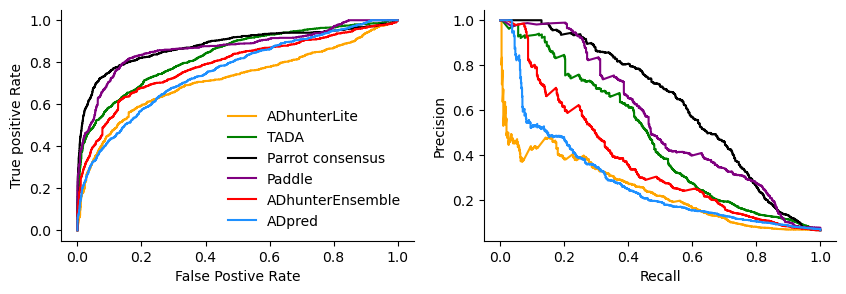

In [17]:
from sklearn.metrics import roc_curve, precision_recall_curve

fig, axs = plt.subplots(1, 2, figsize=(10, 3))

adhunterlite_fpr, adhunterlite_tpr, _ = roc_curve(real_ls, adhunterlite_pred_ls)
tada_fpr, tada_tpr, _ = roc_curve(real_ls, tada_pred_ls)
parrot_fpr, parrot_tpr, _ = roc_curve(real_ls, parrot_ls)
paddle_fpr, paddle_tpr, _ = roc_curve(real_ls, paddle_ls)
adhunter_e_fpr, adhunter_e_tpr, _ = roc_curve(real_ls, adhunterensemble_ls)
adpred_fpr, adpred_tpr, _ = roc_curve(real_ls, adpred_ls)

adhunterlite_prec, adhunterlite_rec, adhunterlite_thresh = precision_recall_curve(real_ls, adhunterlite_pred_ls)
tada_prec, tada_rec, tada_thresh = precision_recall_curve(real_ls, tada_pred_ls)
parrot_prec, parrot_rec, parrot_thresh = precision_recall_curve(real_ls, parrot_ls)
paddle_prec, paddle_rec, paddle_thresh = precision_recall_curve(real_ls, paddle_ls)
adhunter_e_prec, adhunter_e_rec, adhunter_e_thresh = precision_recall_curve(real_ls, adhunterensemble_ls)
adpred_prec, adpred_rec, adpred_thresh = precision_recall_curve(real_ls, adpred_ls)

axs[0].plot(adhunterlite_fpr, adhunterlite_tpr, label='ADhunterLite', color = color_dict['ADhunterLite'])
axs[0].plot(tada_fpr, tada_tpr, label='TADA', color = color_dict['TADA'])
axs[0].plot(parrot_fpr, parrot_tpr, label='Parrot consensus', color = 'black')
axs[0].plot(paddle_fpr, paddle_tpr, label='Paddle', color = color_dict['Paddle'])
axs[0].plot(adhunter_e_fpr, adhunter_e_tpr, label='ADhunterEnsemble', color = color_dict['ADhunterEnsemble'])
axs[0].plot(adpred_fpr, adpred_tpr, label='ADpred', color = color_dict['ADpred'])
axs[0].legend(frameon=False)
axs[0].set_xlabel("False Postive Rate")
axs[0].set_ylabel("True positive Rate")

axs[1].plot(adhunterlite_rec, adhunterlite_prec,  label='ADhunterLite', color = color_dict['ADhunterLite'])
axs[1].plot(tada_rec, tada_prec, label='TADA', color = color_dict['TADA'])
axs[1].plot(parrot_rec, parrot_prec, label='Parrot consensus', color='black')
axs[1].plot(paddle_rec, paddle_prec, label='Paddle', color = color_dict['Paddle'])
axs[1].plot(adhunter_e_rec, adhunter_e_prec, label='ADhunterEnsemble', color = color_dict['ADhunterEnsemble'])
axs[1].plot(adpred_rec, adpred_prec, label='ADpred', color = color_dict['ADpred'])
axs[1].set_xlabel("Recall")
axs[1].set_ylabel("Precision")

sns.despine()

# Doing it the hard way

In [18]:
# Beacuse the threshold biases the F1 score so much, I think PRC curves are a better choice

def calculate_precision_recall_tada(threshold):
    intervals = make_tada_intervals(individual_predictions, threshold)
    if intervals is None: # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))

    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['TADA'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)
    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_paddle(threshold):
    intervals = make_paddle_intervals(individual_predictions, threshold)
    if intervals is None: # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))
    
    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['PADDLE'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)
    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_adhunterlite(threshold):
    intervals = make_adhunter_intervals(individual_predictions, threshold)
    if intervals is None: # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))

    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['ADHunter'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)
    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_adhunterensemble(threshold):
    intervals = make_adhunter_ensemble_intervals(individual_predictions, threshold)
    if intervals is None: # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))

    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['ADHunter_ensemble'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)


    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_adpred(threshold):
    intervals = make_adpred_intervals(individual_predictions, threshold)
    if len(intervals) == 0: # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))

    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['ADPred'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)
    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_parrot(threshold):
    consensus_preds['predicted_AD_coords'] = consensus_preds['preds'].apply(AD_coords, threshold=threshold)

    merged = consensus_preds.merge(data, on=['name', 'sequence'], how='right')
    tp = merged.apply(overlap, ad_coords_col='predicted_AD_coords', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='predicted_AD_coords', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='predicted_AD_coords', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='predicted_AD_coords', axis=1).sum()

    parrot_r = tp / (tp + fn)

    if (tp + fp) == 0: 
        return 0, 1, 0, 0
    else: 
        parrot_p = tp / (tp + fp)

    parrot_tpr = tp / (tp + fn) # This is the same as recall
    parrot_fpr = fp / (fp + tn)

    return parrot_r, parrot_p, parrot_fpr, parrot_tpr



In [19]:
# protein_length-52 -1 is the final tile start

In [20]:
adhunter_e_recalls = []
adhunter_e_precisions = []
adhunter_e_fpr = []
adhunter_e_tpr = []

for threshold in tqdm(adhunter_e_thresh[::]):
    r, p, fpr, tpr = calculate_precision_recall_adhunterensemble(threshold)
    adhunter_e_recalls.append(r)
    adhunter_e_precisions.append(p)    
    adhunter_e_fpr.append(fpr)
    adhunter_e_tpr.append(tpr)

100%|██████████| 12593/12593 [02:50<00:00, 74.06it/s] 


In [21]:
adpred_recalls = []
adpred_precisions = []
adpred_fpr = []
adpred_tpr = []

for threshold in tqdm(adpred_thresh[::]):
    r, p, fpr, tpr = calculate_precision_recall_adpred(threshold)
    adpred_recalls.append(r)
    adpred_precisions.append(p)    
    adpred_fpr.append(fpr)
    adpred_tpr.append(tpr)

100%|██████████| 13893/13893 [01:58<00:00, 116.92it/s]


In [22]:
adhunter_l_recalls = []
adhunter_l_precisions = []
adhunter_l_fpr = []
adhunter_l_tpr = []

for threshold in tqdm(adhunterlite_thresh[::]):
    r, p, fpr, tpr = calculate_precision_recall_adhunterlite(threshold)
    adhunter_l_recalls.append(r)
    adhunter_l_precisions.append(p)    
    adhunter_l_fpr.append(fpr)
    adhunter_l_tpr.append(tpr)

100%|██████████| 12912/12912 [03:12<00:00, 67.23it/s] 


In [23]:
paddle_recalls = []
paddle_precisions = []
paddle_fpr = []
paddle_tpr = []

for threshold in tqdm(paddle_thresh[::]):
    r, p, fpr, tpr = calculate_precision_recall_paddle(threshold)
    paddle_recalls.append(r)
    paddle_precisions.append(p)    
    paddle_fpr.append(fpr)
    paddle_tpr.append(tpr)

100%|██████████| 12591/12591 [04:00<00:00, 52.35it/s] 


In [24]:
tada_recalls = []
tada_precisions = []
tada_fpr = []
tada_tpr = []

for threshold in tqdm(tada_thresh[::]):
    r, p, fpr, tpr = calculate_precision_recall_tada(threshold)
    tada_recalls.append(r)
    tada_precisions.append(p)    
    tada_fpr.append(fpr)
    tada_tpr.append(tpr)

100%|██████████| 12898/12898 [02:43<00:00, 79.00it/s] 


In [25]:
parrot_recalls = []
parrot_precisions = []
parrot_fpr = []
parrot_tpr = []

for threshold in tqdm(parrot_thresh[::]):
    r, p, fpr, tpr = calculate_precision_recall_parrot(threshold)
    parrot_recalls.append(r)
    parrot_precisions.append(p)    
    parrot_fpr.append(fpr)
    parrot_tpr.append(tpr)

100%|██████████| 13888/13888 [00:35<00:00, 396.03it/s]


In [29]:
pd.DataFrame({'parrot_recalls' : parrot_recalls, 
              'parrot_precisions' : parrot_precisions,
              'parrot_fpr' : parrot_fpr,
              'parrot_tpr' : parrot_tpr}).to_csv('delrosso_parrot_roc_prc_data.csv')

In [ ]:
pd.DataFrame({'tada_recalls' : tada_recalls, 
              'tada_precisions' : tada_precisions,
              'tada_fpr' : tada_fpr,
              'tada_tpr' : tada_tpr}).to_csv('delrosso_tada_roc_prc_data.csv')

In [31]:
pd.DataFrame({'paddle_recalls' : paddle_recalls, 
              'paddle_precisions' : paddle_precisions,
              'paddle_fpr' : paddle_fpr,
              'paddle_tpr' : paddle_tpr}).to_csv('delrosso_paddle_roc_prc_data.csv')

In [32]:
pd.DataFrame({'adpred_recalls' : adpred_recalls, 
              'adpred_precisions' : adpred_precisions,
              'adpred_fpr' : adpred_fpr,
              'adpred_tpr' : adpred_tpr}).to_csv('delrosso_adpred_roc_prc_data.csv')

In [33]:
pd.DataFrame({'adhunter_l_recalls' : adhunter_l_recalls, 
              'adhunter_l_precisions' : adhunter_l_precisions,
              'adhunter_l_fpr' : adhunter_l_fpr,
              'adhunter_l_tpr' : adhunter_l_tpr}).to_csv('delrosso_adhunter_l_roc_prc_data.csv')

In [34]:
pd.DataFrame({'adhunter_e_recalls' : adhunter_e_recalls, 
              'adhunter_e_precisions' : adhunter_e_precisions,
              'adhunter_e_fpr' : adhunter_e_fpr,
              'adhunter_e_tpr' : adhunter_e_tpr}).to_csv('delrosso_adhunter_e_roc_prc_data.csv')

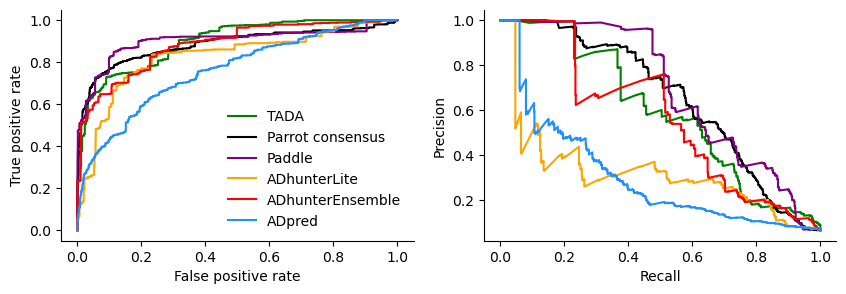

In [35]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3))

axs[0].plot(tada_fpr, tada_tpr, label='TADA', color=color_dict['TADA'])
axs[0].plot(parrot_fpr, parrot_tpr, label='Parrot consensus', color='black')
axs[0].plot(paddle_fpr, paddle_tpr, label='Paddle', color=color_dict['Paddle'])
axs[0].plot(adhunter_l_fpr, adhunter_l_tpr, label='ADhunterLite', color=color_dict['ADhunterLite'])
axs[0].plot(adhunter_e_fpr, adhunter_e_tpr, label='ADhunterEnsemble', color=color_dict['ADhunterEnsemble'])
axs[0].plot(adpred_fpr, adpred_tpr, label='ADpred', color=color_dict['ADpred'])
axs[0].set_xlabel("False positive rate")
axs[0].set_ylabel("True positive rate")
axs[0].legend(frameon=False)

axs[1].plot(tada_recalls, tada_precisions, label='TADA', color=color_dict['TADA'])
axs[1].plot(parrot_recalls, parrot_precisions, label='Parrot consensus', color='black')
axs[1].plot(paddle_recalls, paddle_precisions, label='Paddle', color=color_dict['Paddle']) 
axs[1].plot(adhunter_l_recalls, adhunter_l_precisions, label='ADhunterLite', color=color_dict['ADhunterLite'])
axs[1].plot(adhunter_e_recalls, adhunter_e_precisions, label='ADhunterEnsemble', color=color_dict['ADhunterEnsemble'])
axs[1].plot(adpred_recalls, adpred_precisions, label='ADpred', color=color_dict['ADpred'])
axs[1].set_xlabel("Recall")
axs[1].set_ylabel("Precision")

sns.despine()

In [36]:
from sklearn.metrics import auc

print(f"TADA PRC AUC: {auc(tada_recalls, tada_precisions):.3}")
print(f"Parrot consensus PRC AUC: {auc(parrot_recalls, parrot_precisions):.3}")
print(f"Paddle PRC AUC: {auc(paddle_recalls, paddle_precisions):.3}")
print(f"ADhunterLite PRC AUC: {auc(adhunter_l_recalls, adhunter_l_precisions):.3}")
print(f"ADhunterEnsemble PRC AUC: {auc(adhunter_e_recalls, adhunter_e_precisions):.3}")
print(f"ADpred PRC AUC: {auc(adpred_recalls, adpred_precisions):.3}")

TADA PRC AUC: 0.589
Parrot consensus PRC AUC: 0.649
Paddle PRC AUC: 0.688
ADhunterLite PRC AUC: 0.316
ADhunterEnsemble PRC AUC: 0.559
ADpred PRC AUC: 0.299


In [37]:
print(f"TADA ROC AUC: {auc(tada_fpr, tada_tpr):.3}")
print(f"Parrot consensus ROC AUC: {auc(parrot_fpr, parrot_tpr):.3}")
print(f"Paddle ROC AUC: {auc(paddle_fpr, paddle_tpr):.3}")
print(f"ADhunterLite ROC AUC: {auc(adhunter_l_fpr, adhunter_l_tpr):.3}")
print(f"ADhunterEnsemble ROC AUC: {auc(adhunter_e_fpr, adhunter_e_tpr):.3}")
print(f"ADpred ROC AUC: {auc(adpred_fpr, adpred_tpr):.3}")

TADA ROC AUC: 0.897
Parrot consensus ROC AUC: 0.884
Paddle ROC AUC: 0.904
ADhunterLite ROC AUC: 0.826
ADhunterEnsemble ROC AUC: 0.882
ADpred ROC AUC: 0.759
